# Protokoll Versuch 2: Kalibrierung von Digitalkameras

**Praktikum Technische Grundlagen der KI**
Datum der Messung: 02.11.2026 · Beteiligte: Armin, Mamoon, Pascal

## Ziel und Überblick

Eine Webcam wird als Messinstrument kalibriert. Jeder Pixel hat eine lineare Kennlinie mit eigenem **Nullpunkt** (aus dem Dunkelbild $D$) und eigener **Steigung** (aus dem Weißbild $W$). Daraus folgt die Korrektur

$$I_\text{korr} = \frac{I_\text{roh} - D}{W_\text{norm}}, \qquad W_\text{norm} = \frac{W}{\overline{W}}$$

| Aufgabe | Was gemacht wurde | Kernergebnis | Wichtigste Funktion |
|---|---|---|---|
| 1 | Grauwertkeil aufnehmen, 5 Stufen auswerten | Mittelwerte steigen monoton, $s$ = 3 bis 6 | `stufen_statistik()` |
| 2 | 10 Dunkelbilder mitteln | Dunkelbild überall 0 (Kamera schneidet ab) | `mittelwertbild()`, `dunkelbild_abziehen()` |
| 3 | 10 Weißbilder mitteln, normieren | Weißbild zeigt Flacker-Streifen und Lichtverlauf | `kalibriere()` |
| 4 | Pixelfehler suchen, Keil korrigieren | keine Pixelfehler, $s$ wird größer statt kleiner | `pixelfehler_ersetzen()` |

## Aufbau, Einstellungen und Hilfsfunktionen

- Aufnahme mit OpenCV, verlustfrei als PNG. Die Belichtung wurde einmal manuell eingestellt und danach nicht mehr verändert (Werte unten aus dem Messprotokoll).
- Alle Bilder haben einen 14 Pixel breiten weißen Rahmen. Er ist auch beim abgedeckten Objektiv da, stammt also nicht vom Sensor. Er wird beim Einlesen abgeschnitten (`RAND_PX`).
- Hier stehen nur die allgemeinen Hilfsfunktionen. Die Funktionen einer Aufgabe stehen direkt in dieser Aufgabe.

In [1]:
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from openpyxl import load_workbook
from IPython.display import Markdown, display

BILDER_ORDNER = Path("bilder")
ERGEBNIS_ORDNER = Path("ergebnisse")
ERGEBNIS_ORDNER.mkdir(exist_ok=True)

RAND_PX = 14   # weißer Rahmen um jedes gespeicherte Bild (siehe oben)


def lade_grauwertbild(dateiname):
    """Liest ein PNG, wandelt es in ein Grauwertbild (float64) um und schneidet den Rahmen ab."""
    farbbild = cv2.imread(str(BILDER_ORDNER / dateiname))
    if farbbild is None:
        raise FileNotFoundError(BILDER_ORDNER / dateiname)
    grauwertbild = cv2.cvtColor(farbbild, cv2.COLOR_BGR2GRAY).astype(np.float64)
    return grauwertbild[RAND_PX:-RAND_PX, RAND_PX:-RAND_PX]


def speichere_png(bild, dateiname):
    """Speichert ein float-Bild als 8-Bit-PNG (Werte auf 0..255 begrenzt)."""
    cv2.imwrite(str(ERGEBNIS_ORDNER / dateiname), np.clip(bild, 0, 255).round().astype(np.uint8))


def tabelle(kopfzeile, zeilen):
    """Zeigt eine Ergebnistabelle als Markdown an."""
    text = "| " + " | ".join(kopfzeile) + " |\n|" + "---|" * len(kopfzeile) + "\n"
    text += "\n".join("| " + " | ".join(zeile) + " |" for zeile in zeilen)
    display(Markdown(text))


def de(zahl, stellen=1):
    """Zahl mit Dezimalkomma formatieren."""
    return f"{zahl:.{stellen}f}".replace(".", ",")

In [2]:
# Kameraeinstellungen aus dem Messprotokoll lesen (Spalte A = Bezeichnung, Spalte B = Wert)
protokoll = load_workbook("Messprotokoll_Versuch2.xlsx", data_only=True).active
einstellungen = {
    bezeichnung: wert
    for bezeichnung, wert in protokoll.iter_rows(min_col=1, max_col=2, values_only=True)
    if isinstance(bezeichnung, str) and ("propId" in bezeichnung or bezeichnung.startswith("Auto-Belichtung"))
}
tabelle(["Einstellung", "Wert"], [[name.rstrip(":"), str(wert)] for name, wert in einstellungen.items()])

| Einstellung | Wert |
|---|---|
| Brightness (propId 10) | 128 |
| Contrast (propId 11) | 32 |
| Saturation (propId 12) | 32 |
| Gain (propId 14) | 32 |
| Exposure (propId 15) | -7 |
| White Balance (propId 17) | 3910 |
| Auto-Belichtung deaktiviert? | ja |

Exposure $-7$ bedeutet eine Belichtungszeit von $2^{-7}\,\mathrm{s} \approx 7{,}8\,\mathrm{ms}$. Das wird in Aufgabe 3 wichtig.

## Aufgabe 1: Grauwertkeil

> **Kurz:** Fünf Stufen per Index-Slicing ausschneiden, pro Stufe Mittelwert und Standardabweichung berechnen. Die Mittelwerte steigen monoton, keine Stufe ist gesättigt, die Streuung liegt bei 3 bis 6 Grauwerten.

### 1.1 Lage der Stufen

Der Keil hat fünf senkrechte Stufen (Sollwerte 0, 63, 126, 190, 254). Die Stufengrenzen liegen etwas schräg, deshalb hält jede ROI mindestens 15 Pixel Abstand zu den Rändern (rote Rechtecke).

Bildgröße nach Zuschnitt: 592 x 444 Pixel
Min / Max Grauwert: 1 / 254


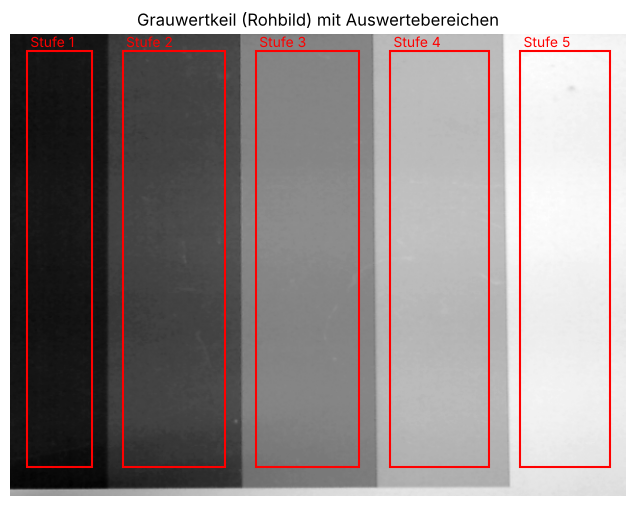

In [3]:
grauwertkeil_roh = lade_grauwertbild("grauwertkeil.png")

SOLLWERTE_VORLAGE = [0, 63, 126, 190, 254]
ROI_ZEILEN = slice(16, 416)                 # gemeinsamer Zeilenbereich aller Stufen
ROI_SPALTEN = [slice(16, 78), slice(108, 206), slice(236, 335), slice(365, 460), slice(490, 576)]


def stufen_statistik(bild):
    """Mittelwert und Standardabweichung der Grauwerte jeder Stufe."""
    unterbilder = [bild[ROI_ZEILEN, spalten] for spalten in ROI_SPALTEN]
    # ddof=1: empirische Standardabweichung der Messwerte (nicht die des Mittelwerts)
    return [(unterbild.mean(), unterbild.std(ddof=1), unterbild.size) for unterbild in unterbilder]


print(f"Bildgröße nach Zuschnitt: {grauwertkeil_roh.shape[1]} x {grauwertkeil_roh.shape[0]} Pixel")
print(f"Min / Max Grauwert: {grauwertkeil_roh.min():.0f} / {grauwertkeil_roh.max():.0f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(grauwertkeil_roh, cmap="gray", vmin=0, vmax=255)
for nummer, spalten in enumerate(ROI_SPALTEN, start=1):
    ax.add_patch(Rectangle((spalten.start, ROI_ZEILEN.start), spalten.stop - spalten.start,
                           ROI_ZEILEN.stop - ROI_ZEILEN.start, fill=False, edgecolor="red", lw=1.5))
    ax.text(spalten.start + 3, ROI_ZEILEN.start - 4, f"Stufe {nummer}", color="red")
ax.set_title("Grauwertkeil (Rohbild) mit Auswertebereichen")
ax.axis("off")
plt.show()

### 1.2 Mittelwert und Standardabweichung der Stufen

In [4]:
statistik_roh = stufen_statistik(grauwertkeil_roh)

tabelle(["Stufe", "Sollwert Vorlage", "Pixel in ROI", "Mittelwert", "Standardabweichung s"],
        [[str(nummer), str(soll), str(anzahl), de(mittel), de(streuung, 2)]
         for nummer, (soll, (mittel, streuung, anzahl)) in enumerate(zip(SOLLWERTE_VORLAGE, statistik_roh), start=1)])

mittelwerte_roh = [mittel for mittel, _, _ in statistik_roh]
assert all(np.diff(mittelwerte_roh) > 0), "Die Stufen müssen von links nach rechts heller werden"

| Stufe | Sollwert Vorlage | Pixel in ROI | Mittelwert | Standardabweichung s |
|---|---|---|---|---|
| 1 | 0 | 24800 | 20,6 | 2,79 |
| 2 | 63 | 39200 | 67,3 | 5,96 |
| 3 | 126 | 39600 | 133,2 | 4,32 |
| 4 | 190 | 38000 | 186,4 | 3,89 |
| 5 | 254 | 34400 | 242,6 | 5,40 |

- **Keine Sättigung:** dunkelste Stufe ≈ 21 (nicht 0), hellste ≈ 243 (nicht 255).
- **Ungleiche Stufenabstände:** Die Webcam bildet Helligkeit nicht linear ab (Gamma), und Papier ist nie ideal schwarz oder weiß.
- **Streuung $s$ = 3 bis 6**, obwohl jede Stufe konstant sein sollte: Sensorrauschen, ungleichmäßige Beleuchtung, Vignettierung, Kratzer auf der Vorlage.

## Aufgabe 2: Dunkelbild

> **Kurz:** 10 Aufnahmen mit abgedecktem Objektiv pixelweise mitteln. Ergebnis: Das Dunkelbild ist überall exakt 0, die Korrektur ändert also nichts.

### 2.1 Mittelung der 10 Dunkelaufnahmen

Der pixelweise Mittelwert ist das Dunkelbild $D(x,y)$, also der Nullpunkt jedes Pixels. Durch die Mittelung fällt das zufällige Ausleserauschen heraus.

In [5]:
def mittelwertbild(dateimuster):
    """Pixelweiser Mittelwert aller Bilder, deren Name zum Muster passt (z.B. 'dunkel_*.png')."""
    dateien = sorted(BILDER_ORDNER.glob(dateimuster))
    bilderstapel = np.stack([lade_grauwertbild(datei.name) for datei in dateien])
    return bilderstapel.mean(axis=0), len(dateien)


def zeige_kontrastmaximiert(ax, bild, titel):
    """Zeigt ein Bild mit gestreckter Grauwertskala (Minimum = schwarz, Maximum = weiß)."""
    anzeige = ax.imshow(bild, cmap="gray", vmin=bild.min(), vmax=max(bild.max(), bild.min() + 1))
    ax.set_title(titel)
    ax.axis("off")
    plt.colorbar(anzeige, ax=ax, fraction=0.035)

10 Aufnahmen gemittelt
Dunkelbild: Min 0.00, Max 0.00, Mittelwert 0.000
Alle 10 Einzelaufnahmen identisch: True


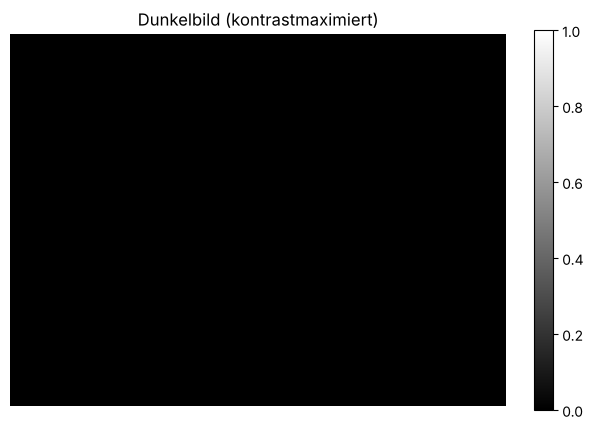

In [6]:
dunkelbild, anzahl_dunkel = mittelwertbild("dunkel_*.png")
np.save(ERGEBNIS_ORDNER / "dunkelbild.npy", dunkelbild)   # float-Version für die Korrektur
speichere_png(dunkelbild, "dunkelbild.png")

einzelbilder_dunkel = [lade_grauwertbild(f"dunkel_{nummer:02d}.png") for nummer in range(1, anzahl_dunkel + 1)]
alle_identisch = all(np.array_equal(einzelbild, einzelbilder_dunkel[0]) for einzelbild in einzelbilder_dunkel)

print(f"{anzahl_dunkel} Aufnahmen gemittelt")
print(f"Dunkelbild: Min {dunkelbild.min():.2f}, Max {dunkelbild.max():.2f}, Mittelwert {dunkelbild.mean():.3f}")
print(f"Alle 10 Einzelaufnahmen identisch: {alle_identisch}")

fig, ax = plt.subplots(figsize=(7, 5))
zeige_kontrastmaximiert(ax, dunkelbild, "Dunkelbild (kontrastmaximiert)")
plt.show()

**Ergebnis:** Das Dunkelbild ist überall 0, und alle 10 Aufnahmen sind identisch. Deshalb ist auch das kontrastmaximierte Bild schwarz.

- **Warum?** Die Webcam zieht intern einen Schwarzwert ab und schneidet alles darunter auf 0 ab (Clipping). Bei 7,8 ms Belichtung kommen Dunkelstrom und Rauschen nicht über diese Schwelle.
- **Folge:** Die Dunkelbildkorrektur ändert bei uns nichts. Die Routine wird trotzdem umgesetzt, damit sie bei einer Kamera mit echtem Offset funktioniert.

### 2.2 Routine zur Dunkelbildkorrektur

In [7]:
def dunkelbild_abziehen(eingabebild, dunkelbild):
    """Zieht den pixelweisen Nullpunkt (Dunkelbild) vom Eingabebild ab."""
    return eingabebild - dunkelbild


grauwertkeil_ohne_dunkel = dunkelbild_abziehen(grauwertkeil_roh, dunkelbild)
speichere_png(grauwertkeil_ohne_dunkel, "grauwertkeil_dunkelkorrigiert.png")
print("Maximale Änderung durch die Dunkelbildkorrektur:", np.abs(grauwertkeil_ohne_dunkel - grauwertkeil_roh).max())

Maximale Änderung durch die Dunkelbildkorrektur: 0.0


## Aufgabe 3: Weißbild

> **Kurz:** 10 Aufnahmen eines weißen Blattes mitteln, Dunkelbild abziehen, auf Mittelwert 1 normieren. Das Weißbild zeigt aber nicht nur die Kamera, sondern auch Flacker-Streifen und einen Lichtverlauf.

### 3.1 Mittelung der 10 Weißaufnahmen

Das Blatt wurde im gleichen Abstand wie der Keil aufgenommen. Weißbild $W$ = Mittelwert der 10 Aufnahmen minus Dunkelbild.

10 Aufnahmen gemittelt
Weißbild: Min 20.8, Max 238.0, Mittelwert 168.7 (= 66 % der Hellsättigung)
Gesättigte Pixel in einer Einzelaufnahme: 0.00 %


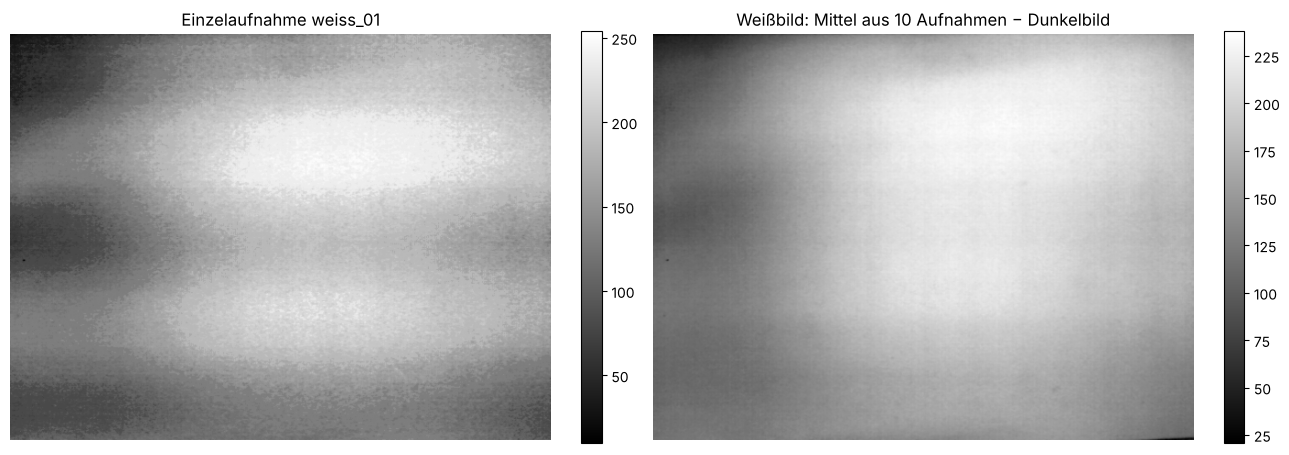

In [8]:
weiss_mittelwert, anzahl_weiss = mittelwertbild("weiss_*.png")
weissbild = dunkelbild_abziehen(weiss_mittelwert, dunkelbild)
np.save(ERGEBNIS_ORDNER / "weissbild.npy", weissbild)
speichere_png(weissbild, "weissbild.png")

einzelbild_weiss = lade_grauwertbild("weiss_01.png")
anteil_gesaettigt = np.mean(einzelbild_weiss >= 255) * 100

print(f"{anzahl_weiss} Aufnahmen gemittelt")
print(f"Weißbild: Min {weissbild.min():.1f}, Max {weissbild.max():.1f}, Mittelwert {weissbild.mean():.1f} "
      f"(= {weissbild.mean() / 255 * 100:.0f} % der Hellsättigung)")
print(f"Gesättigte Pixel in einer Einzelaufnahme: {anteil_gesaettigt:.2f} %")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
zeige_kontrastmaximiert(axs[0], einzelbild_weiss, "Einzelaufnahme weiss_01")
zeige_kontrastmaximiert(axs[1], weissbild, "Weißbild: Mittel aus 10 Aufnahmen − Dunkelbild")
plt.tight_layout()
plt.show()

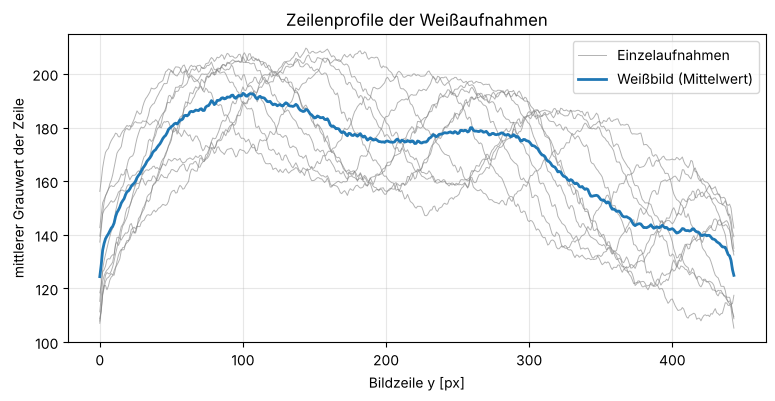

In [9]:
# Zeilenprofile: mittlerer Grauwert jeder Bildzeile, einmal pro Einzelaufnahme und für das gemittelte Weißbild
fig, ax = plt.subplots(figsize=(9, 4))
for nummer in range(1, anzahl_weiss + 1):
    zeilenprofil = lade_grauwertbild(f"weiss_{nummer:02d}.png").mean(axis=1)
    ax.plot(zeilenprofil, color="gray", lw=0.7, alpha=0.6, label="Einzelaufnahmen" if nummer == 1 else None)
ax.plot(weissbild.mean(axis=1), color="C0", lw=2, label="Weißbild (Mittelwert)")
ax.set_xlabel("Bildzeile y [px]")
ax.set_ylabel("mittlerer Grauwert der Zeile")
ax.set_title("Zeilenprofile der Weißaufnahmen")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Beobachtungen:**

- **Wandernde Streifen (graue Kurven):** Die Raumbeleuchtung flackert mit 100 Hz, also mit einer Periode von 10 ms. Die Webcam liest zeilenweise aus (Rolling Shutter), und 7,8 ms Belichtung sind kürzer als eine Periode. Deshalb bekommen die Zeilen unterschiedlich viel Licht. 10 Bilder mitteln das nur teilweise heraus (blaue Kurve).
- **Lichtverlauf:** Das Blatt ist in der Mitte heller als am Rand, durch Vignettierung und ungleichmäßige Beleuchtung.
- **Helligkeit:** 66 % der Hellsättigung statt der geforderten 30 bis 50 %, aber kein Pixel gesättigt.

**Folge:** Das Weißbild enthält auch das Licht während seiner Aufnahme. Das war bei der Keilaufnahme anders, und das zeigt sich in Aufgabe 4.

### 3.2 Erweiterte Korrekturroutine

Weißbild auf Mittelwert 1 normieren, dann das dunkelbildkorrigierte Bild pixelweise dadurch teilen.

In [10]:
weissbild_normiert = weissbild / weissbild.mean()
assert np.isclose(weissbild_normiert.mean(), 1.0)
assert weissbild_normiert.min() > 0, "Division durch 0: Weißbild enthält Pixel ohne Signal"


def kalibriere(eingabebild, dunkelbild, weissbild_normiert):
    """Dunkelbild abziehen und durch das normierte Weißbild teilen (Nullpunkt und Steigung jedes Pixels)."""
    return dunkelbild_abziehen(eingabebild, dunkelbild) / weissbild_normiert


print(f"Normiertes Weißbild: Min {weissbild_normiert.min():.2f}, Max {weissbild_normiert.max():.2f}")

Normiertes Weißbild: Min 0.12, Max 1.41


## Aufgabe 4: Pixelfehler und Überprüfung

> **Kurz:** Keine defekten Pixel gefunden. Der kalibrierte Keil ist ungleichmäßiger als der rohe: $s$ steigt in allen Stufen, weil das Weißbild vom Licht und nicht von der Kamera geprägt ist.

### 4.1 Suche nach defekten Pixeln

- **Stuck/hot pixels:** helle Punkte im Dunkelbild, Dunkelwert über `SCHWELLE_HOT`.
- **Dead pixels:** dunkle Punkte im Weißbild. Weil das Weißbild großflächig schwankt, wird mit dem Median der 5×5-Nachbarschaft verglichen, nicht mit einem festen Wert.

Gefundene Pixel würden rot umkreist.

Stuck/hot pixels im Dunkelbild: 0
Dead pixels im Weißbild:       0
Dunkelste Abweichung im Weißbild: 61 % des lokalen Medians


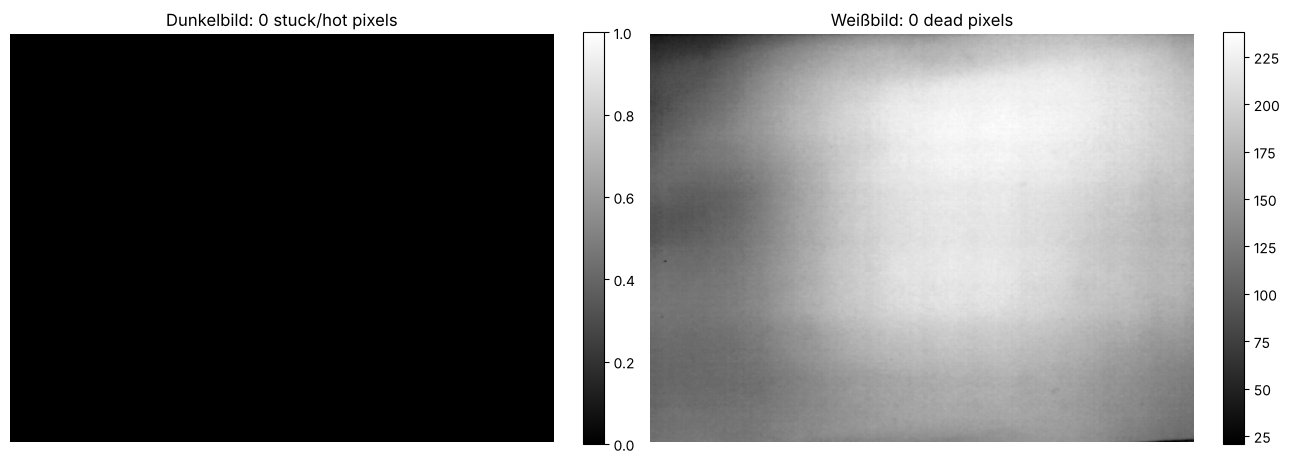

In [11]:
SCHWELLE_HOT = 20      # Grauwert im Dunkelbild, ab dem ein Pixel als stuck/hot gilt
FAKTOR_DEAD = 0.5      # dead, wenn heller als nur 50 % des lokalen Medians im Weißbild

weissbild_lokaler_median = cv2.medianBlur(weissbild.astype(np.float32), 5)
maske_hot = dunkelbild > SCHWELLE_HOT
maske_dead = weissbild < FAKTOR_DEAD * weissbild_lokaler_median
maske_defekt = maske_hot | maske_dead

print(f"Stuck/hot pixels im Dunkelbild: {maske_hot.sum()}")
print(f"Dead pixels im Weißbild:       {maske_dead.sum()}")
print(f"Dunkelste Abweichung im Weißbild: {np.min(weissbild / weissbild_lokaler_median) * 100:.0f} % des lokalen Medians")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
zeige_kontrastmaximiert(axs[0], dunkelbild, f"Dunkelbild: {maske_hot.sum()} stuck/hot pixels")
zeige_kontrastmaximiert(axs[1], weissbild, f"Weißbild: {maske_dead.sum()} dead pixels")
for ax, maske in zip(axs, [maske_hot, maske_dead]):
    zeilen, spalten = np.nonzero(maske)
    ax.scatter(spalten, zeilen, s=80, facecolors="none", edgecolors="red")
plt.tight_layout()
plt.savefig(ERGEBNIS_ORDNER / "pixelfehler.png", dpi=120)
plt.show()

**Keine defekten Pixel gefunden.**

- **Dunkelbild:** Wegen des Clippings auf 0 kann hier gar kein hot pixel auftauchen.
- **Weißbild:** Kein Pixel ist deutlich dunkler als seine Umgebung. Der dunkle Punkt am linken Rand ist mehrere Pixel groß, also eher ein Fleck auf dem Papier.
- Webcams rechnen defekte Pixel meist schon intern heraus. Die Ersetzung durch den Nachbarschafts-Median ist trotzdem eingebaut, ersetzt bei uns aber nichts.

### 4.2 Korrektur des Grauwertkeils

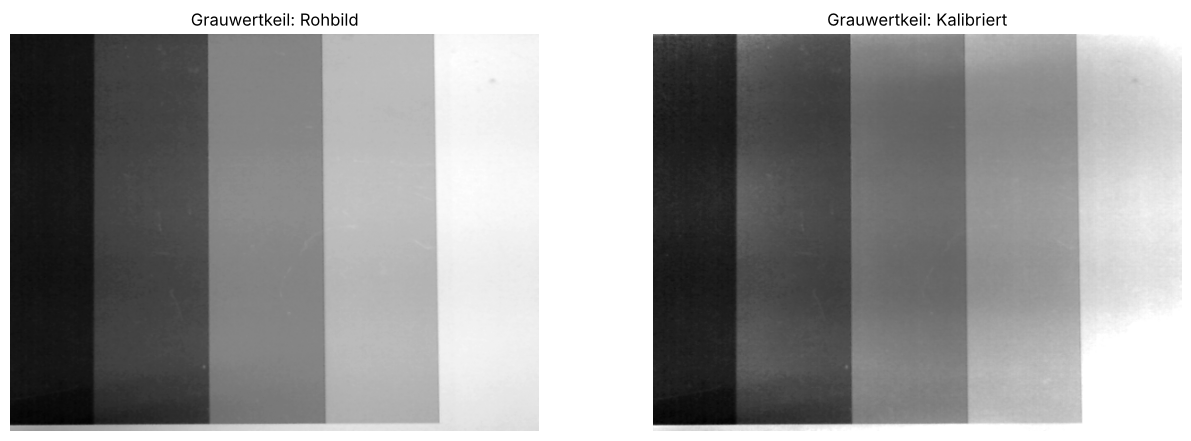

In [12]:
def pixelfehler_ersetzen(bild, maske_defekt):
    """Ersetzt defekte Pixel durch den Median ihrer 5x5-Nachbarschaft."""
    median_bild = cv2.medianBlur(bild.astype(np.float32), 5)
    return np.where(maske_defekt, median_bild, bild)


grauwertkeil_korrigiert = pixelfehler_ersetzen(
    kalibriere(grauwertkeil_roh, dunkelbild, weissbild_normiert), maske_defekt)
speichere_png(grauwertkeil_korrigiert, "grauwertkeil_korrigiert.png")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, bild, titel in zip(axs, [grauwertkeil_roh, grauwertkeil_korrigiert], ["Rohbild", "Kalibriert"]):
    ax.imshow(bild, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Grauwertkeil: {titel}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3 Vergleich vor und nach der Korrektur

| Stufe | Mittelwert roh | s roh | Mittelwert korrigiert | s korrigiert | Änderung von s |
|---|---|---|---|---|---|
| 1 | 20,6 | 2,79 | 32,3 | 6,01 | +115 % |
| 2 | 67,3 | 5,96 | 75,3 | 8,33 | +40 % |
| 3 | 133,2 | 4,32 | 113,1 | 10,24 | +137 % |
| 4 | 186,4 | 3,89 | 155,6 | 15,74 | +304 % |
| 5 | 242,6 | 5,40 | 231,3 | 29,93 | +454 % |

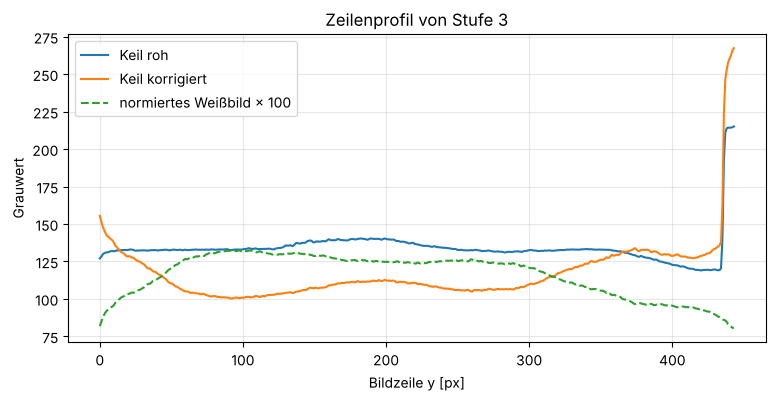

In [13]:
statistik_korrigiert = stufen_statistik(grauwertkeil_korrigiert)

tabelle(["Stufe", "Mittelwert roh", "s roh", "Mittelwert korrigiert", "s korrigiert", "Änderung von s"],
        [[str(nummer), de(mittel_roh), de(s_roh, 2), de(mittel_korr), de(s_korr, 2), f"{(s_korr / s_roh - 1) * 100:+.0f} %"]
         for nummer, ((mittel_roh, s_roh, _), (mittel_korr, s_korr, _))
         in enumerate(zip(statistik_roh, statistik_korrigiert), start=1)])

# Zeilenprofil der mittleren Stufe: zeigt, woher die zusätzliche Streuung kommt
mittlere_stufe = ROI_SPALTEN[2]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grauwertkeil_roh[:, mittlere_stufe].mean(axis=1), label="Keil roh")
ax.plot(grauwertkeil_korrigiert[:, mittlere_stufe].mean(axis=1), label="Keil korrigiert")
ax.plot(100 * weissbild_normiert[:, mittlere_stufe].mean(axis=1), "--", label="normiertes Weißbild × 100")
ax.set_xlabel("Bildzeile y [px]")
ax.set_ylabel("Grauwert")
ax.set_title("Zeilenprofil von Stufe 3")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Ergebnis: Keine Verbesserung, sondern eine Verschlechterung.** $s$ steigt in allen Stufen, bei den hellen auf ein Mehrfaches.

**Grund (Zeilenprofil):** Der rohe Keil ist entlang der Zeilen fast flach. Das normierte Weißbild schwankt dagegen zwischen 0,8 am Rand und 1,3 in der Mitte. Beim Teilen wird dieses Muster spiegelverkehrt in den Keil übertragen. Das Weißbild beschreibt also vor allem das Licht bei seiner eigenen Aufnahme:

1. **Lichtflackern:** Die Streifen liegen in jedem Bild woanders, 10 Bilder mitteln sie nicht heraus.
2. **Ausleuchtung des Blattes:** Ungleichmäßige Helligkeit wird fälschlich als Vignettierung interpretiert.
3. **Dunkelbild:** Durch das Clipping auf 0 korrigiert es nichts.

Dass sich die Mittelwerte der Stufen verschieben, ist dagegen erwartet: Das Teilen durch $W_\text{norm}$ hebt oder senkt Bereiche je nach lokaler Empfindlichkeit.

## Fazit

Das Verfahren aus Dunkel- und Weißbild ist korrekt umgesetzt: Ein Pixel wird über Nullpunkt und Steigung seiner Kennlinie korrigiert, defekte Pixel werden gesucht und ersetzt. Mit unseren Aufnahmen bringt es aber keine Verbesserung, weil das Weißbild von der Beleuchtung dominiert wird und das Dunkelbild durch die Kameraelektronik auf 0 abgeschnitten ist.

Für eine bessere Kalibrierung müsste man:

- die Belichtungszeit auf ein Vielfaches von 10 ms stellen (z.B. Exposure $-6$, also $2^{-6}\,\mathrm{s} \approx 15{,}6\,\mathrm{ms}$, oder genau 10/20 ms, falls einstellbar). Alternativ mit flackerfreiem Licht arbeiten, z.B. Tageslicht oder Gleichstrom-LED.
- das Weißblatt gleichmäßig und ohne Schatten ausleuchten, bei 30 bis 50 % der Hellsättigung.
- mehr als 10 Weißbilder mitteln oder das Blatt leicht defokussiert aufnehmen, damit Papierstruktur und Flecken verschwinden.
- für das Dunkelbild Kameraeinstellungen wählen, bei denen der Schwarzwert nicht abgeschnitten wird (Brightness erhöhen), damit Offset und hot pixels überhaupt messbar sind.

Die korrigierten Bilder liegen im Ordner `ergebnisse/` (`dunkelbild.png`, `weissbild.png`, `grauwertkeil_dunkelkorrigiert.png`, `grauwertkeil_korrigiert.png`, `pixelfehler.png`).